<a href="https://colab.research.google.com/github/Carhl89/An-lisis-Futbol-Argentino/blob/main/Analisis_Futbol_Argentino_Python_SQL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("¡Comienza nuestro proyecto de analisis de datos de futbol!")

¡Comienza nuestro proyecto de analisis de datos de futbol!


# Analisis de Futbol Argentino con **Python, SQL** y ***Pandas***

 Proyecto de Analisis de datos con Python, SQL, Pandas y Matplotlib

In [ ]:
import pandas as pd

In [ ]:
partidos = {
    "Local" : ["River Plate", "Boca Juniors", "Racing Club"],
    "Visitante" : ["Boca Juniors", "Racing Club", "River Plate"],
    "Goles_local" : [2,1,0],
    "Goles_visitante" : [1,1,2]
}

In [ ]:
df = pd.DataFrame(partidos)

In [ ]:
df

,Local,Visitante,Goles_local,Goles_visitante
0,River Plate,Boca Juniors,2,1
1,Boca Juniors,Racing Club,1,1
2,Racing Club,River Plate,0,2


In [ ]:
def resultado(fila):
  if fila["Goles_local"]> fila ["Goles_visitante"]:
    return "Gana local"
  elif fila ["Goles_local"]< fila ["Goles_visitante"]:
      return "Gana visitante"
  else:
       return "Empate"
df["Resultado"]= df.apply(resultado,axis=1)
df


,Local,Visitante,Goles_local,Goles_visitante,Resultado
0,River Plate,Boca Juniors,2,1,Gana local
1,Boca Juniors,Racing Club,1,1,Empate
2,Racing Club,River Plate,0,2,Gana visitante


In [ ]:
def puntos(fila):
  if fila["Resultado"]=="Gana local":
    return 3
  elif fila["Resultado"] =="Gana visitante":
    return 0
  else:
    return 1
df["Puntos_local"] = df.apply(puntos, axis=1)
df

,Local,Visitante,Goles_local,Goles_visitante,Resultado,Puntos_local
0,River Plate,Boca Juniors,2,1,Gana local,3
1,Boca Juniors,Racing Club,1,1,Empate,1
2,Racing Club,River Plate,0,2,Gana visitante,0


In [ ]:
def Puntos_visitante(fila):
  if fila["Goles_visitante"] > fila["Goles_local"]:
    return 3
  elif fila ["Goles_visitante"] < fila["Goles_local"]:
    return 0
  else:
     1
df["Puntos_visitante"]= df.apply(Puntos_visitante, axis=1)
df


,Local,Visitante,Goles_local,Goles_visitante,Resultado,Puntos_local,Puntos_visitante
0,River Plate,Boca Juniors,2,1,Gana local,3,0.0
1,Boca Juniors,Racing Club,1,1,Empate,1,NaN
2,Racing Club,River Plate,0,2,Gana visitante,0,3.0


In [ ]:
df.columns

Index(['Local', 'Visitante', 'Goles_local', 'Goles_visitante', 'Resultado',
       'Puntos_local', 'Puntos_visitante'],
      dtype='object')

In [ ]:
equipos = ["River Plate", "Boca Juniors", "Racing Club"]
tabla = []
for equipo in equipos:
  partidos_jugados = (
      len(df[df["Local"] == equipo]) + len(df[df["Visitante"] == equipo])
  )
puntos = (
    df.loc[df["Local"] == equipo, "Puntos_local"].sum()
    + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
tabla.append({
    "Equipos":equipo,
    "Partidos":partidos_jugados,
    "Puntos":puntos
})
posiciones = pd.DataFrame(tabla)
posiciones =posiciones.sort_values(
    by= "Puntos", ascending=False
)
posiciones

,Equipos,Partidos,Puntos
0,Racing Club,2,0.0


In [ ]:
print(df)

          Local     Visitante  Goles_local  Goles_visitante       Resultado  \
0   River Plate  Boca Juniors            2                1      Gana local   
1  Boca Juniors   Racing Club            1                1          Empate   
2   Racing Club   River Plate            0                2  Gana visitante   

   Puntos_local  Puntos_visitante  
0             3               0.0  
1             1               NaN  
2             0               3.0  


In [ ]:
print(posiciones)

       Equipos  Partidos  Puntos
0  Racing Club         2     0.0


In [ ]:

equipos = sorted(set(df["Local"]) | set(df["Visitante"]))
tabla = []
for  equipo in equipos:
  partidos_jugados = (
      (df["Local"] == equipo).sum()
      + (df["Visitante"] == equipo).sum()
  )
  puntos = (
      df.loc[df["Local"] == equipo, "Puntos_local"].sum()
      + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
  tabla.append({
      "Equipo": equipo,
      "Partido": partidos_jugados,
      "Puntos": puntos
  })
  posiciones = pd.DataFrame(tabla)
  posiciones = posiciones.sort_values(
      by="Puntos", ascending=False
  ).reset_index(drop=True)
posiciones



,Equipo,Partido,Puntos
0,River Plate,2,6.0
1,Boca Juniors,2,1.0
2,Racing Club,2,0.0


In [ ]:
print(posiciones.to_string(index=False))

      Equipo  Partido  Puntos
 River Plate        2     6.0
Boca Juniors        2     1.0
 Racing Club        2     0.0


In [ ]:
equipos = sorted(set(df["Local"]) | set (df["Visitante"]))
tabla = []
for equipo in equipos:
  goles_favor = (
      df.loc[df["Local"] == equipo, "Goles_local"].sum() + df.loc[df["Visitante"] == equipo, "Goles_visitante"].sum()
  )
  goles_contra = (
      df.loc[df["Local"] == equipo, "Goles_visitante"].sum()
      + df.loc[df["Visitante"] == equipo, "Goles_local"].sum()
  )
  diferencia = goles_favor - goles_contra
  puntos = (
      df.loc[df["Local"] == equipo, "Puntos_local"].sum()
      + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
  tabla.append({
      "Equipo": equipo,
      "GF": goles_favor,
      "GC": goles_contra,
      "DG": diferencia,
      "Puntos": puntos
  })
  posiciones = pd.DataFrame(tabla)
  posiciones = posiciones.sort_values(
      by=["Puntos", "DG"],
      ascending=[False,False]
  ).reset_index(drop=True)
  posiciones


In [ ]:
print(posiciones)

         Equipo  GF  GC  DG  Puntos
0   River Plate   4   1   3     6.0
1  Boca Juniors   2   3  -1     1.0
2   Racing Club   1   3  -2     0.0


In [ ]:
posiciones["PJ"] = posiciones["Equipo"].apply(
    lambda equipo: (
        (df["Local"] == equipo).sum()
        + (df["Visitante"] == equipo).sum()
    )
)
posiciones

,Equipo,GF,GC,DG,Puntos,PJ
0,River Plate,4,1,3,6.0,2
1,Boca Juniors,2,3,-1,1.0,2
2,Racing Club,1,3,-2,0.0,2


In [ ]:
def contar_victorias(equipo):
  local = ((df["Local"] == equipo) & (df["Resultado"]== "Gana local")).sum()
  visitante =((df["Visitante"] == equipo) & (df["Resultado"] == "Gana visitante")).sum()
  return local + visitante
def contar_empates(equipo):
  return (
      ((df["Local"] == equipo) & (df['Visitante'] == equipo) & (df["Resultado"] == "Empate"))
  ).sum()
def contar_derrotas(equipo):
  local = ((df["Local"] == equipo) & (df["Resultado"] == "Gana visitante")).sum()
  visitante =((df["Visitante"] == equipo) & (df["Resultado"] == "Gana local")).sum()
  return local + visitante

posiciones["PG"] = posiciones["Equipo"].apply(contar_victorias)
posiciones["PE"] =  posiciones["Equipo"].apply(contar_empates)
posiciones["PP"] = posiciones["Equipo"].apply(contar_derrotas)

posiciones

,Equipo,GF,GC,DG,Puntos,PJ,PG,PE,PP
0,River Plate,4,1,3,6.0,2,2,0,0
1,Boca Juniors,2,3,-1,1.0,2,0,0,1
2,Racing Club,1,3,-2,0.0,2,0,0,1


In [ ]:
import matplotlib.pyplot as plt


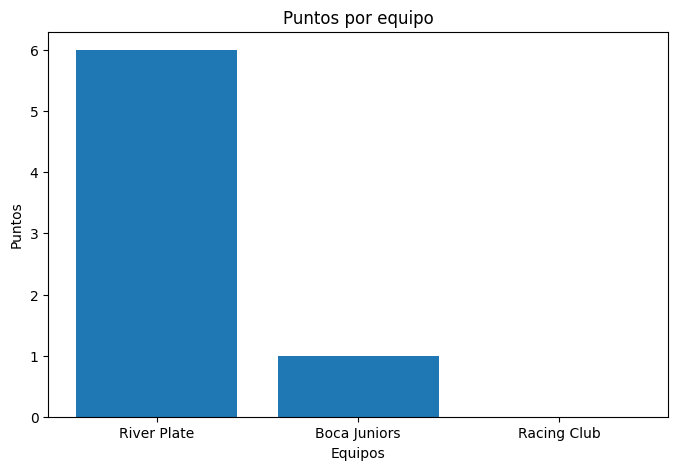

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(posiciones["Equipo"], posiciones["Puntos"])

plt.title("Puntos por equipo")
plt.xlabel("Equipos")
plt.ylabel("Puntos")
plt.show()

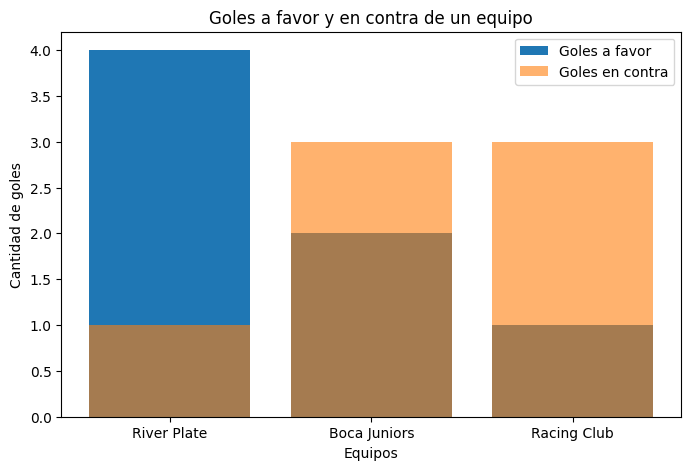

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    posiciones["Equipo"],
    posiciones["GF"],
    label = "Goles a favor"
)

plt.bar(
    posiciones["Equipo"],
    posiciones["GC"],
    label="Goles en contra",
    alpha=0.6
)

plt.title("Goles a favor y en contra de un equipo")
plt.xlabel("Equipos")
plt.ylabel("Cantidad de goles")
plt.legend()

plt.show()

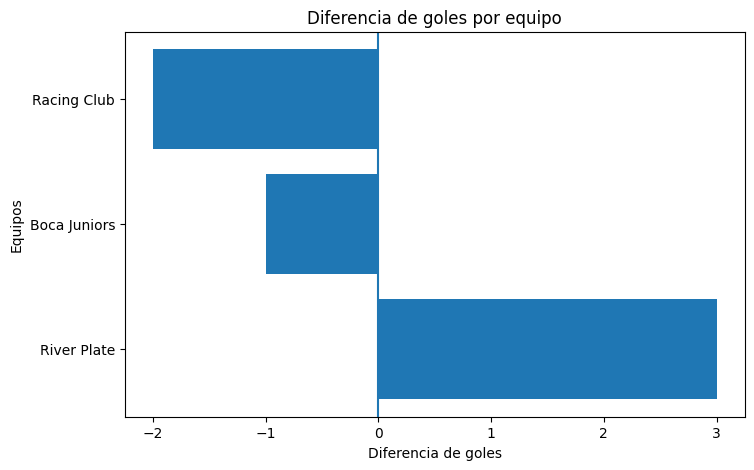

In [ ]:
plt.figure(figsize=(8,5))

plt.barh(
    posiciones["Equipo"],
    posiciones["DG"]
)

plt.title("Diferencia de goles por equipo")
plt.xlabel("Diferencia de goles")
plt.ylabel("Equipos")
plt.axvline(x=0)
plt.show()

In [1]:
import sqlite3
import pandas as pd
conexion = sqlite3.connect("futbol_argentino.db")
print("Base de datos conectada cprrectamente")

Base de datos conectada cprrectamente


In [10]:
consulta = """
CREATE TABLE IF NOT EXISTS equipos (
id INTEGER PRIMARY KEY AUTOINCREMENT,
nombre TEXT NOT NULL,
ciudad TEXT
);
"""
conexion.execute(consulta)
print("Tabla equipos creada correctamente")

Tabla equipos creada correctamente


In [11]:
consulta = """
INSERT INTO equipos(nombre, ciudad) VALUES
("River Plate","Buenos Aires"),
("Boca Juniors", "BUenos Aires"),
("Racing Club", " Avellaneda");
"""
conexion.execute(consulta)
conexion.commit()
print("Equipos cargadoscorrectamente")

Equipos cargadoscorrectamente


In [12]:
consulta = "SELECT *FROM equipos"
resultado = pd.read_sql_query(consulta, conexion)
resultado

,id,nombre,ciudad
0,1,River Plate,Buenos Aires
1,2,Boca Juniors,BUenos Aires
2,3,Racing Club,Avellaneda


In [14]:
consulta = """
CREATE TABLE IF NOT EXISTS partidos (
id INTEGER PRIMARY KEY AUTOINCREMENT,
equipo_local TEXT NOT NULL,
equipo_visitante  TEXT NOT NULL,
goles_local INTEGER,
goles_visitante INTEGER,
fecha TEXT
);
"""
conexion.execute(consulta)
print(" Tabla partidos creada correctamente")

 Tabla partidos creada correctamente


In [16]:
consulta= """
SELECT *FROM partidos;
"""
partidos_sql = pd.read_sql_query(consulta, conexion)
partidos_sql

,id,equipo_local,equipo_visitante,goles_local,goles_visitante,fecha


In [20]:
consulta = """
INSERT INTO partidos
(equipo_local, equipo_visitante, goles_local, goles_visitante, fecha)
VALUES
("River Plate", "Boca Juniors", 2,1, "2026-10-01"),
("Boca Juniors", "Racing Club", 1,1, "2026-10-08"),
("Racing Club", "River Plate", 0,2, "2026-10-15");
"""
conexion.execute(consulta)
conexion.commit()
print("Partidos cargados correctamente")

Partidos cargados correctamente


In [21]:
partidos_sql = pd.read_sql_query(
    "SELECT *FROM partidos",
    conexion
)
print(partidos_sql)

   id  equipo_local equipo_visitante  goles_local  goles_visitante       fecha
0   1   River Plate     Boca Juniors            2                1  2026-10-01
1   2  Boca Juniors      Racing Club            1                1  2026-10-08
2   3   Racing Club      River Plate            0                2  2026-10-15


In [25]:
consulta = """
SELECT * FROM partidos
WHERE equipo_local = "River Plate"
OR equipo_visitante = "River Plate";
"""
river = pd.read_sql_query(consulta, conexion)
river

,id,equipo_local,equipo_visitante,goles_local,goles_visitante,fecha
0,1,River Plate,Boca Juniors,2,1,2026-10-01
1,3,Racing Club,River Plate,0,2,2026-10-15


In [26]:
consulta = """
SELECT
equipo_local, COUNT(*) AS cantidad_partidos
FROM partidos
GROUP BY equipo_local
ORDER BY cantidad_partidos DESC;
"""
resumen =pd.read_sql_query(consulta, conexion)
resumen

,equipo_local,cantidad_partidos
0,River Plate,1
1,Racing Club,1
2,Boca Juniors,1


In [29]:
consulta = """
SELECT equipo, SUM(goles) AS goles_a_favor FROM
(
SELECT equipo_local AS equipo, goles_local AS goles FROM partidos
UNION ALL
SELECT equipo_visitante AS equipo, goles_visitante AS goles FROM partidos
)
GROUP BY equipo
ORDER BY goles_a_favor DESC;
"""
goles_equipos = pd.read_sql_query(consulta, conexion)
goles_equipos

,equipo,goles_a_favor
0,River Plate,4
1,Boca Juniors,2
2,Racing Club,1


In [30]:
consulta = """
SELECT equipo, SUM(goles) AS goles_en_contra
FROM(
SELECT equipo_local AS equipo, goles_visitante AS goles FROM partidos
UNION ALL
SELECT equipo_visitante AS equipo, goles_local AS goles
FROM partidos
)
GROUP BY equipo
ORDER BY goles_en_contra DESC;
"""
goles_recibidos = pd.read_sql_query(consulta, conexion)
goles_recibidos

,equipo,goles_en_contra
0,Racing Club,3
1,Boca Juniors,3
2,River Plate,1


In [54]:
consulta = """
WITH estadisticas AS (
SELECT
equipo_local AS equipo,
goles_local AS gf,
goles_visitante AS gc
FROM partidos

UNION ALL

SELECT
equipo_visitante AS equipo,
goles_visitante AS gf,
goles_local AS gc
FROM partidos

)
SELECT
equipo,
SUM(gf) AS  GF,
SUM(gc) AS GC,
SUM(gf) - SUM(gc) AS DG
FROM estadisticas

GROUP BY equipo
ORDER BY DG DESC;
"""
tabla_sql = pd.read_sql_query(consulta, conexion)
tabla_sql

,equipo,GF,GC,DG
0,River Plate,4,1,3
1,Boca Juniors,2,3,-1
2,Racing Club,1,3,-2


In [56]:
consulta = """
WITH resultados AS (

SELECT
equipo_local AS equipo,
goles_local AS gf,
goles_visitante AS gc,

CASE
 WHEN goles_local > goles_visitante THEN 3
 WHEN goles_local = goles_visitante THEN 1
 ELSE 0
END AS puntos,

CASE WHEN goles_local > goles_visitante THEN 1 ELSE 0
END AS PG,
 CASE WHEN goles_local = goles_visitante THEN 1 ELSE 0
END AS PE,
 CASE WHEN goles_local < goles_visitante THEN 1 ELSE 0
END AS PP

FROM partidos

UNION ALL

SELECT

equipo_visitante AS equipo,
goles_visitante AS gf,
goles_local AS gc,

CASE
 WHEN goles_visitante > goles_local THEN 3
 WHEN goles_visitante = goles_local THEN 1
   ELSE 0
END AS puntos,

 CASE WHEN goles_visitante > goles_local THEN 1 ELSE 0
END AS PG,
 CASE WHEN goles_visitante = goles_local THEN 1 ELSE 0
END AS PE,
 CASE WHEN goles_visitante < goles_local THEN 1 ELSE 0
END AS PP

FROM partidos
)
SELECT
equipo AS Equipo,
COUNT(*) AS PJ,
SUM(PG) AS PG,
SUM(PE) AS PE,
SUM(PP) AS PP,
SUM(gf) AS GF,
SUM(gc) AS GC,
SUM(gf) - SUM(gc) AS DG,
SUM(puntos) AS Puntos

FROM resultados
GROUP BY equipo
ORDER BY Puntos DESC, DG DESC;
"""
tabla_sql = pd.read_sql_query(consulta, conexion)
tabla_sql

,Equipo,PJ,PG,PE,PP,GF,GC,DG,Puntos
0,River Plate,2,2,0,0,4,1,3,6
1,Boca Juniors,2,0,1,1,2,3,-1,1
2,Racing Club,2,0,1,1,1,3,-2,1


In [58]:
tabla_sql["Control_PJ"] = (
    tabla_sql["PG"]+
    tabla_sql["PE"]+
    tabla_sql["PP"]
)
tabla_sql["Control_Puntos"] = (
    tabla_sql["PG"]* 3 +
    tabla_sql["PE"]
)
tabla_sql["Control_DG"] = (
    tabla_sql["GF"] - tabla_sql["GC"]
)
tabla_sql

,Equipo,PJ,PG,PE,PP,GF,GC,DG,Puntos,Control_PJ,Control_Puntos,Control_DG,Control_PJ,Control_Puntos
0,River Plate,2,2,0,0,4,1,3,6,2,6,3,2,6
1,Boca Juniors,2,0,1,1,2,3,-1,1,2,1,-1,2,1
2,Racing Club,2,0,1,1,1,3,-2,1,2,1,-2,2,1


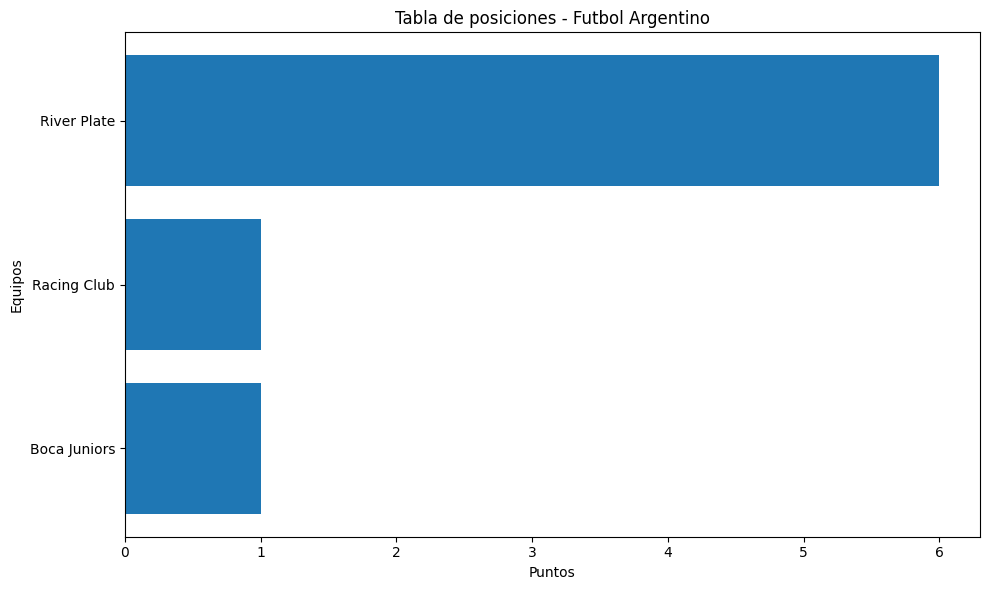

In [59]:
import matplotlib.pyplot as plt

tabla_grafico = tabla_sql.sort_values(
    by= "Puntos",
    ascending=True
)
plt.figure(figsize=(10,6))
plt.barh(
    tabla_grafico["Equipo"],
    tabla_grafico["Puntos"]
)
plt.title("Tabla de posiciones - Futbol Argentino")
plt.xlabel("Puntos")
plt.ylabel("Equipos")

plt.tight_layout()
plt.show()

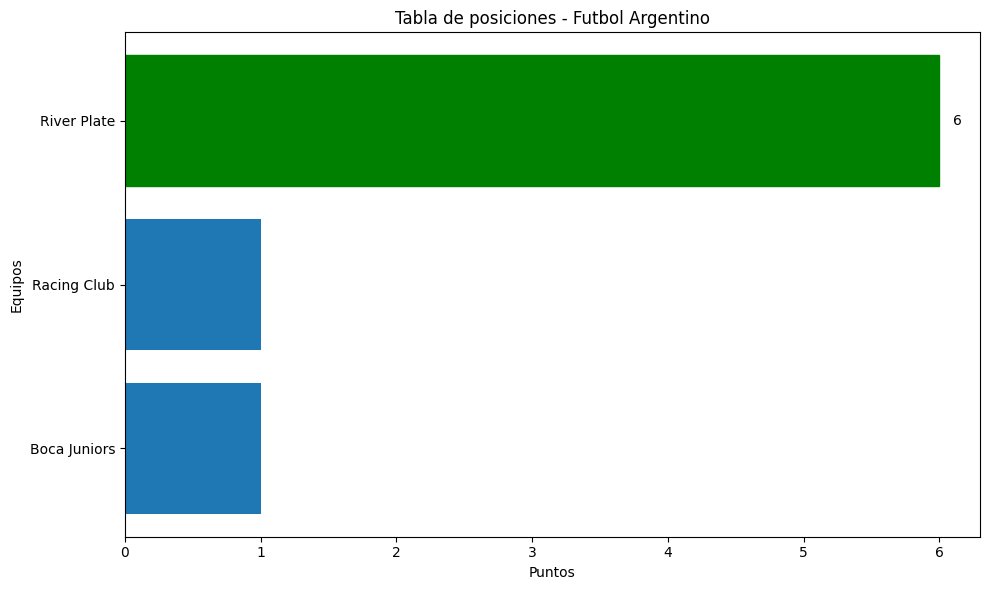

In [62]:
import matplotlib.pyplot as plt

tabla_grafico = tabla_sql.sort_values(
    by="Puntos",
    ascending=True
)
plt.figure(figsize=(10,6))

barras = plt.barh(
    tabla_grafico["Equipo"],
    tabla_grafico["Puntos"]
)
# Destacar al equipo lider
barras[-1].set_color("green")
# Mostrar los puntos al lado de cada barra
for barra in barras:
  puntos = barra.get_width()

plt.text(
    puntos + 0.1,
    barra.get_y() + barra.get_height()/2,
    str(int(puntos)),
    va="center"
)
plt.title("Tabla de posiciones - Futbol Argentino")
plt.xlabel("Puntos")
plt.ylabel("Equipos")

plt.tight_layout()
plt.savefig("tabla_posiciones_futbol.png", dpi=300,bbox_inches="tight")
plt.show()

In [63]:
from google.colab import files
files.download("tabla_posiciones_futbol.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>